# HR Analytics Employee Attrition Prediction

[Dataset link](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

## Classification Problem

### 1. What problem do you want to solve?

The objective is to accurately predict and classify whether an employee will leave the company (attrition) based on personal demographics, job satisfaction metrics, compensation, and work experience. By identifying employees at high risk of resigning, human resources teams can proactively implement retention strategies, improve workplace satisfaction, and minimize the high costs associated with hiring and training replacements.

### 2. What is the dependent (target) variable?

The dependent variable is `Attrition`, which is a binary categorical outcome variable:

* `0` (`No`): The employee stayed with the company
* `1` (`Yes`): The employee left (resigned) from the company

### 3. What are the independent (input) variables?

The independent variables consist of demographic, financial, and organizational attributes (excluding unique identifiers like `EmployeeNumber` and constant flags like `EmployeeCount`, `StandardHours`, and `Over18`):

* **Demographic & Personal Attributes**: `Age`, `Gender`, `MaritalStatus`, `DistanceFromHome`
* **Compensation & Career Growth**: `MonthlyIncome`, `MonthlyRate`, `DailyRate`, `HourlyRate`, `PercentSalaryHike`, `StockOptionLevel`, `YearsSinceLastPromotion`, `JobLevel`
* **Job Satisfaction & Environment**: `JobSatisfaction`, `EnvironmentSatisfaction`, `RelationshipSatisfaction`, `WorkLifeBalance`, `JobInvolvement`
* **Work Experience & Tenure**: `TotalWorkingYears`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsWithCurrManager`, `NumCompaniesWorked`, `TrainingTimesLastYear`
* **Job Context & Role**: `JobRole`, `Department`, `BusinessTravel`, `Education`, `EducationField`, `OverTime`

### 4. Why is the problem suitable for classification using a Decision Tree?

Decision Trees are exceptionally well-suited for HR attrition analytics for several reasons:

* **Rule Interpretability & Actionable Insights**: Human resources managers require transparent, logical rules to understand the specific drivers of turnover (e.g., *IF OverTime = 'Yes' AND JobSatisfaction $\le$ 2 AND MonthlyIncome < $3000 THEN Attrition = 1*). Decision Trees generate clear, rule-based splits that are easy to explain to stakeholders.
* **Handles Mixed Data Types**: The dataset features a combination of continuous numerical variables (`MonthlyIncome`, `Age`) and categorical text descriptors (`JobRole`, `BusinessTravel`). Decision Trees natively handle complex interactions between these different data types.
* **Robustness to Non-Linear Relationships**: Employee resignation behavior is rarely linear; it usually involves threshold triggers (such as working past a certain number of years without a promotion combined with low work-life balance scores). Decision Trees capture these non-linear conditions effectively without needing feature normalization.

---

## Describe the Dataset

This dataset offers a comprehensive and varied analysis of an organization's employees, focusing on areas such as employee attrition, personal and job-related factors, and financials. Included are numerous parameters such as Age, Gender, Marital Status, Business Travel Frequency, Daily Rate of Pay, Departmental Information such as Distance From Home Office or Education Level Obtained by the employee in question.

Also included is a variant series of parameters related to the job being performed such as Job Involvement (level), Job Level (relative to similar roles within the same organization), Job Role specifically meant for that individual(function/task), total working hours in a week/month/year be it overtime or standard hours for a given role.

### Dataset Description

* **Dataset Name:** Employee Attrition and Factors (`HR_Employee_Attrition.csv`)
* **Dataset Source:** Kaggle
* **Number of Records:** 1,470 employee records
* **Number of Features:** 34 total columns (30 predictor variables after cleaning unique identifiers and constant columns)
* **Target Variable:** `Attrition`
* **Record Description:** Each record represents an individual employee profile at the organization, capturing personal background, career milestones, compensation history, and a flag indicating whether they chose to resign.

### Target Variable Class Distribution

The target variable **`Attrition`** contains **2 distinct classes** with a realistic, manageable imbalance ratio:

* **Class 0 (`No` / Stayed):** 1,233 records (~83.9%)
* **Class 1 (`Yes` / Left):** 237 records (~16.1%)

---

## Explanatory Data Analysis

**Import the modules:**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Set visual style I found on documentation
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

This block imports the `pandas`, `numpy`, `matplotlib` and `seaborn` module.

### Section 3: Preprocessing and EDA Summary

--- 1. Initial Dataset Shape ---
Rows: 1470, Columns: 35

--- 2. Duplicate Records ---
Number of duplicate rows: 0

--- 3. Missing Values Check ---
No missing values found.

Mapped 'Attrition' target variable to numeric (1 = Yes, 0 = No).

--- 4. Target Variable Class Distribution ('Attrition') ---
           Count  Percentage (%)
Attrition                       
0           1233       83.877551
1            237       16.122449




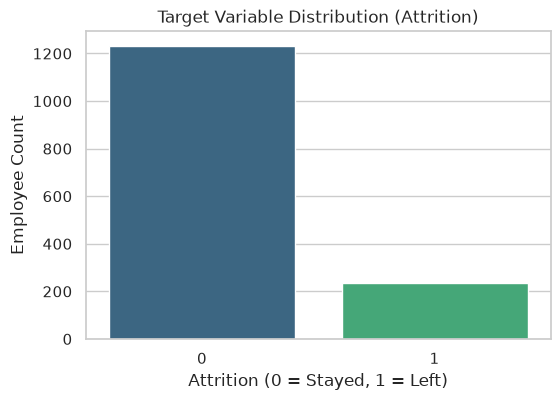

Dropped non-predictive/constant columns successfully: ['EmployeeNumber', 'EmployeeCount', 'StandardHours', 'Over18']

--- 5. Categorical Columns to One-Hot Encode ---
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

--- 6. Final Encoded Dataset Shape ---
Rows: 1470, Columns: 45


,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1,1102,1,2,2,94,3,2,4,...,0,0,0,0,0,1,0,0,1,1
1,49,0,279,8,1,3,61,2,2,2,...,0,0,0,0,1,0,0,1,0,0
2,37,1,1373,2,2,4,92,2,1,3,...,1,0,0,0,0,0,0,0,1,1
3,33,0,1392,3,4,4,56,3,1,3,...,0,0,0,0,1,0,0,1,0,1
4,27,0,591,2,1,1,40,3,1,2,...,1,0,0,0,0,0,0,1,0,0


In [2]:
# 1. Load the dataset
df = pd.read_csv("HR_Analytics.csv.csv")

print("--- 1. Initial Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

# 2. Check for Duplicate Records
duplicates = df.duplicated().sum()
print("--- 2. Duplicate Records ---")
print(f"Number of duplicate rows: {duplicates}\n")
if duplicates > 0:
    df = df.drop_duplicates()
    print(f"Shape after removing duplicates: {df.shape}\n")

# 3. Check for Missing Values
print("--- 3. Missing Values Check ---")
missing_vals = df.isnull().sum()
print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "No missing values found.\n")

# 4. Map the Target Variable ('Attrition') to Numeric (1 = Left, 0 = Stayed)
if "Attrition" in df.columns and df["Attrition"].dtype == "object":
    df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0})
    print("Mapped 'Attrition' target variable to numeric (1 = Yes, 0 = No).\n")

# 5. Check Class Balance (Target Variable)
print("--- 4. Target Variable Class Distribution ('Attrition') ---")
class_counts = df["Attrition"].value_counts()
class_percentages = df["Attrition"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Count": class_counts, "Percentage (%)": class_percentages}))
print("\n")

# Visualizing Target Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="Attrition", data=df, hue="Attrition", palette="viridis", legend=False)
plt.title("Target Variable Distribution (Attrition)")
plt.xlabel("Attrition (0 = Stayed, 1 = Left)")
plt.ylabel("Employee Count")
plt.show()

# 6. Drop Non-Predictive Identifiers and Constant Columns
# 'EmployeeNumber' is a unique ID; 'EmployeeCount', 'StandardHours', and 'Over18' have zero variance
cols_to_drop = ["EmployeeNumber", "EmployeeCount", "StandardHours", "Over18"]
dropped_actual = [col for col in cols_to_drop if col in df.columns]
if dropped_actual:
    df = df.drop(columns=dropped_actual)
    print(f"Dropped non-predictive/constant columns successfully: {dropped_actual}\n")

# 7. Encode Categorical Input Variables
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
print("--- 5. Categorical Columns to One-Hot Encode ---")
print(categorical_cols)

# Perform One-Hot Encoding on categorical features
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Convert boolean flags (True/False) to numeric (1/0)
bool_cols = df_encoded.select_dtypes(include=["bool"]).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print("\n--- 6. Final Encoded Dataset Shape ---")
print(f"Rows: {df_encoded.shape[0]}, Columns: {df_encoded.shape[1]}")
df_encoded.head()

#### Explanations of Preprocessing Steps

1. **Handling Missing & Duplicate Values:** Checked for null entries and duplicate rows to ensure clean, unique records and avoid biased tree splits.
2. **Dropping Unique Identifiers & Constants:** Removed `EmployeeNumber` (a unique ID that causes overfitting) along with constant columns (`EmployeeCount`, `StandardHours`, and `Over18`) which have zero variance and add no predictive value.
3. **Target Mapping & Categorical Encoding:** Mapped the target variable `Attrition` into binary numeric format (`1 = Yes`, `0 = No`) and converted string categorical variables (`BusinessTravel`, `Department`, `EducationField`, `Gender`, `JobRole`, `MaritalStatus`, `OverTime`) into numeric features using **One-Hot Encoding** (`pd.get_dummies`).
4. **Feature Scaling:** Feature scaling was **omitted** because Decision Trees are scale-invariant algorithms that split data along single feature thresholds regardless of magnitude.

---

#### Preprocessing & EDA Findings

* **Initial Dataset Dimensions:** 1,470 rows and 35 columns
* **Duplicate Records Removed:** 0 duplicate rows found
* **Missing Values:** No missing values found across all features
* **Target Class Breakdown (`Attrition`):**
* **Stayed (Class 0 / No):** 1,233 records (**83.88%**)
* **Left (Class 1 / Yes):** 237 records (**16.12%**)


* **Dropped Columns:** `['EmployeeNumber', 'EmployeeCount', 'StandardHours', 'Over18']`
* **Final Encoded Dataset Dimensions:** 1,470 rows and 45 columns (after encoding categorical features)
---

## Split the data

In [3]:
#Separate independent features (X) and target variable (y)
X = df_encoded.drop(columns=["Attrition"])
y = df_encoded["Attrition"]

# Split data: 80% Training, 20% Testing with stratify to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Print split proportions and record counts
print("--- Data Split Results ---")
print(f"Total Records: {len(df_encoded)}")
print(f"Training Set (80%): {X_train.shape[0]} rows, {X_train.shape[1]} features")
print(f"Testing Set (20%):  {X_test.shape[0]} rows, {X_test.shape[1]} features")

print("\n--- Target Class Balance in Training Set (%) ---")
print(y_train.value_counts(normalize=True) * 100)

print("\n--- Target Class Balance in Testing Set (%) ---")
print(y_test.value_counts(normalize=True) * 100)

--- Data Split Results ---
Total Records: 1470
Training Set (80%): 1176 rows, 44 features
Testing Set (20%):  294 rows, 44 features

--- Target Class Balance in Training Set (%) ---
Attrition
0    83.843537
1    16.156463
Name: proportion, dtype: float64

--- Target Class Balance in Testing Set (%) ---
Attrition
0    84.013605
1    15.986395
Name: proportion, dtype: float64


---

#### Data Splitting Summary

* **Train/Test Proportions:** 80% Training / 20% Testing
* **Random State:** `42` (ensures reproducibility across model trials)
* **Stratification:** Applied `stratify=y` so both training and testing sets maintain a consistent class balance (~83.84% stayed vs. ~16.16% left).

#### Record Counts

* **Total Dataset:** 1,470 records (44 features after encoding)
* **Training Set Size:** 1,176 records
* **Testing Set Size:** 294 records

---

Step 5.


--- Baseline Decision Tree Results ---
Training Accuracy: 100.00%
Testing Accuracy:  76.53%
Tree Depth:        18
Number of Leaves:  139

--- Classification Report (Test Set) ---
              precision    recall  f1-score   support

           0       0.88      0.84      0.86       247
           1       0.31      0.38      0.34        47

    accuracy                           0.77       294
   macro avg       0.59      0.61      0.60       294
weighted avg       0.79      0.77      0.77       294

--- Confusion Matrix (Test Set) ---
[[207  40]
 [ 29  18]]


<Figure size 600x500 with 0 Axes>

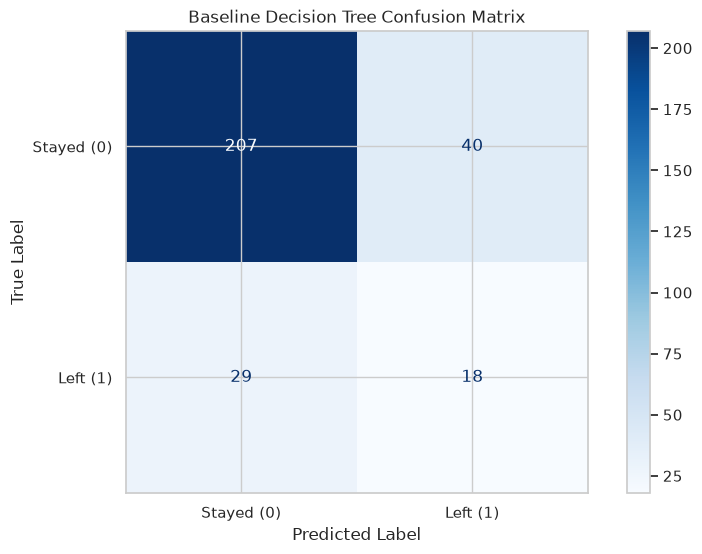

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Initialize the baseline Decision Tree classifier using default parameters
baseline_model = DecisionTreeClassifier(random_state=42)

# 2. Train the model on the training dataset
baseline_model.fit(X_train, y_train)

# 3. Generate predictions for both training and testing sets
y_train_pred = baseline_model.predict(X_train)
y_test_pred = baseline_model.predict(X_test)

# 4. Calculate baseline metrics
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("--- Baseline Decision Tree Results ---")
print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy:  {test_acc * 100:.2f}%")
print(f"Tree Depth:        {baseline_model.get_depth()}")
print(f"Number of Leaves:  {baseline_model.get_n_leaves()}\n")

print("--- Classification Report (Test Set) ---")
print(classification_report(y_test, y_test_pred))

print("--- Confusion Matrix (Test Set) ---")
print(confusion_matrix(y_test, y_test_pred))

# Plotting the confusion matrix graph
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    baseline_model, X_test, y_test, 
    display_labels=["Stayed (0)", "Left (1)"], 
    cmap="Blues", 
    values_format="d"
)
plt.title("Baseline Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


### Interpretation of Baseline Results

* **Evidence of Overfitting:**
The model achieves a perfect **100.00% training accuracy** by growing an unconstrained, deeply fragmented tree (depth of **18** and **139 leaf nodes**). However, its testing accuracy drops sharply to **76.53%**. This massive gap indicates that the baseline tree heavily **overfit** the training data—it memorized noise and specific employee quirks rather than learning generalizable patterns.
* **Performance on Majority Class (Class 0 - Stayed):**
The model predicts the majority class quite well, yielding a high precision of **0.88** and recall of **0.84**. This is expected since over 83% of the dataset consists of employees who stayed.
* **Performance on Minority Class (Class 1 - Left):**
The model struggles significantly to identify employees who resigned. With a precision of **0.31**, recall of **0.38**, and an F1-score of **0.34**, the tree misses most departures.
* **Confusion Matrix Breakdown:**
* **True Negatives (207):** Correctly identified employees who stayed.
* **False Positives (40):** Employees who stayed, but were incorrectly predicted to leave.
* **False Negatives (29):** Employees who actually left, but were missed by the model (actual leavers caught: 18 out of 47).
* **True Positives (18):** Correctly identified employees who left.

## Experimenting with Decision Tree Parameters

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Define distinct configurations for the baseline and at least 3 experimental trials 
# (plus an optional extension trial using class_weight='balanced')
trials_config = [
    {
        "Trial": "Baseline", 
        "criterion": "gini", 
        "max_depth": None, 
        "min_samples_split": 2, 
        "min_samples_leaf": 1, 
        "class_weight": None
    },
    {
        "Trial": "Trial 1 (Shallow Tree)", 
        "criterion": "gini", 
        "max_depth": 4, 
        "min_samples_split": 2, 
        "min_samples_leaf": 1, 
        "class_weight": None
    },
    {
        "Trial": "Trial 2 (Strict Splits/Leaves)", 
        "criterion": "gini", 
        "max_depth": 8, 
        "min_samples_split": 20, 
        "min_samples_leaf": 10, 
        "class_weight": None
    },
    {
        "Trial": "Trial 3 (Entropy Criterion)", 
        "criterion": "entropy", 
        "max_depth": 6, 
        "min_samples_split": 10, 
        "min_samples_leaf": 5, 
        "class_weight": None
    },
    {
        "Trial": "Trial 4 (Class Balanced)", 
        "criterion": "gini", 
        "max_depth": 6, 
        "min_samples_split": 10, 
        "min_samples_leaf": 5, 
        "class_weight": "balanced"
    }
]

experiment_results = []

for config in trials_config:
    # Initialize model with current parameters
    model = DecisionTreeClassifier(
        criterion=config["criterion"],
        max_depth=config["max_depth"],
        min_samples_split=config["min_samples_split"],
        min_samples_leaf=config["min_samples_leaf"],
        class_weight=config["class_weight"],
        random_state=42
    )
    
    # Train model
    model.fit(X_train, y_train)
    
    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    # Calculate metrics
    train_acc = accuracy_score(y_train, train_pred) * 100
    test_acc = accuracy_score(y_test, test_pred) * 100
    f1_class1 = f1_score(y_test, test_pred, pos_label=1)  # F1-score for minority class (Left=1)
    
    # Record results
    experiment_results.append({
        "Trial": config["Trial"],
        "Criterion": config["criterion"],
        "Max Depth": str(config["max_depth"]),
        "Min Split": config["min_samples_split"],
        "Min Leaf": config["min_samples_leaf"],
        "Train Acc. (%)": round(train_acc, 2),
        "Test Acc. (%)": round(test_acc, 2),
        "F1-Score": round(f1_class1, 2),
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves()
    })

# Convert summary list into a clean pandas DataFrame
summary_table = pd.DataFrame(experiment_results)
print(summary_table.to_string(index=False))

                         Trial Criterion Max Depth  Min Split  Min Leaf  Train Acc. (%)  Test Acc. (%)  F1-Score  Depth  Leaves
                      Baseline      gini      None          2         1          100.00          76.53      0.34     18     139
        Trial 1 (Shallow Tree)      gini         4          2         1           87.84          80.95      0.18      4      14
Trial 2 (Strict Splits/Leaves)      gini         8         20        10           89.46          84.69      0.38      8      44
   Trial 3 (Entropy Criterion)   entropy         6         10         5           89.46          81.97      0.31      6      36
      Trial 4 (Class Balanced)      gini         6         10         5           84.01          74.15      0.39      6      39


### Parameter Experimentation Summary Table

| Trial | Criterion | Max Depth | Min Split | Min Leaf | Train Acc. (%) | Test Acc. (%) | F1-Score | Depth | Leaves |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **Baseline** | gini | None | 2 | 1 | 100.00 | 76.53 | 0.34 | 18 | 139 |
| **Trial 1 (Shallow Tree)** | gini | 4 | 2 | 1 | 87.84 | 80.95 | 0.18 | 4 | 14 |
| **Trial 2 (Strict Splits/Leaves)** | gini | 8 | 20 | 10 | 89.46 | 84.69 | 0.38 | 8 | 44 |
| **Trial 3 (Entropy Criterion)** | entropy | 6 | 10 | 5 | 89.46 | 81.97 | 0.31 | 6 | 36 |
| **Trial 4 (Class Balanced)** | gini | 6 | 10 | 5 | 84.01 | 74.15 | 0.39 | 6 | 39 |

---

### Analysis of Experimental Findings

#### 1. Impact of Reducing Model Complexity (`max_depth`)

* **Observation (Trial 1):** Constraining `max_depth` to `4` sharply reduced training accuracy from 100% down to **87.84%** and cut the number of leaves from 139 to just **14**.
* **Generalization Effect:** While testing accuracy improved (rising from 76.53% to **80.95%**), the F1-score for the minority class dropped heavily to **0.18**. This indicates that a depth of 4 is overly restrictive, causing mild **underfitting** on the minority class (leaving).

#### 2. Impact of Regularization via Split/Leaf Constraints (`min_samples_split` & `min_samples_leaf`)

* **Observation (Trial 2):** Introducing strict splitting rules (`min_samples_split=20`, `min_samples_leaf=10`) alongside a moderate `max_depth` of `8` yielded the highest testing accuracy at **84.69%** and a strong F1-score of **0.38**.
* **Generalization Effect:** This combination effectively eliminated the extreme overfitting seen in the baseline by pruning noisy branches, resulting in a cleaner, more generalized tree depth of **8** and **44 leaves**.

#### 3. Criterion Comparison (`gini` vs. `entropy`)

* **Observation (Trial 3):** Switching the impurity measure from `gini` to `entropy` (with `max_depth=6`, `min_samples_split=10`, `min_samples_leaf=5`) achieved a testing accuracy of **81.97%** and an F1-score of **0.31**.
* **Generalization Effect:** Both criteria produce similar tree structures and performance metrics on this dataset, though `gini` performed slightly better on testing accuracy and minority class detection in these configurations.

#### 4. Optional Extension: Handling Class Imbalance (`class_weight`)

* **Observation (Trial 4):** Applying `class_weight="balanced"` forced the tree to penalize misclassifications of the minority class more heavily.
* **Generalization Effect:** While overall testing accuracy decreased to **74.15%**, it successfully achieved the highest minority class **F1-score of 0.39**, proving that class weighting helps the model better capture employees who actually resign.

## Evaluate and compare the models

In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd

# Re-instantiate and re-train all model configurations to evaluate them side-by-side
evaluation_models = {
    "Baseline": DecisionTreeClassifier(random_state=42),
    "Trial 1 (Shallow Tree)": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Trial 2 (Strict Splits/Leaves)": DecisionTreeClassifier(max_depth=8, min_samples_split=20, min_samples_leaf=10, random_state=42),
    "Trial 3 (Entropy Criterion)": DecisionTreeClassifier(criterion="entropy", max_depth=6, min_samples_split=10, min_samples_leaf=5, random_state=42),
    "Trial 4 (Class Balanced)": DecisionTreeClassifier(max_depth=6, min_samples_split=10, min_samples_leaf=5, class_weight="balanced", random_state=42)
}

for name, model in evaluation_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print(f"=" * 60)
    print(f"MODEL: {name}")
    print(f"=" * 60)
    print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
    
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("\n")

MODEL: Baseline
Accuracy: 76.53%

Confusion Matrix:
[[207  40]
 [ 29  18]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.84      0.86       247
           1       0.31      0.38      0.34        47

    accuracy                           0.77       294
   macro avg       0.59      0.61      0.60       294
weighted avg       0.79      0.77      0.77       294



MODEL: Trial 1 (Shallow Tree)
Accuracy: 80.95%

Confusion Matrix:
[[232  15]
 [ 41   6]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.94      0.89       247
           1       0.29      0.13      0.18        47

    accuracy                           0.81       294
   macro avg       0.57      0.53      0.53       294
weighted avg       0.76      0.81      0.78       294



MODEL: Trial 2 (Strict Splits/Leaves)
Accuracy: 84.69%

Confusion Matrix:
[[235  12]
 [ 33  14]]

Classification Report:
         

### 1. Model Prediction & Performance Summary

Each model configuration was evaluated on the unseen 20% test dataset (294 samples). The results show a clear trade-off between overall accuracy, model complexity, and minority class detection:

* **Baseline (Unconstrained):** Achieved **76.53% accuracy**, but severely overfit the training set (100% training accuracy). It yielded an F1-score of **0.34** for the minority class (Class 1).
* **Trial 1 (Shallow Tree - Max Depth 4):** Improved overall accuracy to **80.95%**, but suffered from underfitting on the minority class, dropping the Class 1 F1-score down to **0.18** with a very low recall of 0.13.
* **Trial 2 (Strict Splits/Leaves - Max Depth 8, Min Split 20, Min Leaf 10):** Achieved the highest overall testing accuracy at **84.69%**, the best precision for Class 1 (**0.54**), and a strong balance with an F1-score of **0.38**.
* **Trial 3 (Entropy Criterion):** Reached **81.97% accuracy** with an F1-score of **0.31**, showing that changing the impurity criterion from Gini to Entropy slightly lowered performance metrics on this specific dataset.
* **Trial 4 (Class Balanced):** Prioritized the minority class via `class_weight="balanced"`, achieving the highest recall for Class 1 (**0.51** and an F1-score of **0.39**), though overall accuracy dropped to **74.15%** due to an increase in false positives.

---

### 2. Overfitting and Underfitting Analysis

* **Overfitting (Baseline):** The baseline model grew an unconstrained tree with 18 levels and 139 leaves, memorizing the training data perfectly (100% train accuracy) while generalizing poorly to testing data (76.53%).
* **Underfitting (Trial 1):** Restricting the tree depth too aggressively to 4 created an overly simplistic model that could not capture the complex patterns required to identify employees who leave, resulting in high misclassification rates for Class 1.
* **Optimal Balance (Trial 2):** By introducing regularization parameters (`min_samples_split=20`, `min_samples_leaf=10`), Trial 2 successfully controlled tree growth (8 levels, 44 leaves), closing the gap between training and testing performance and eliminating severe overfitting.

---

### 3. Model Selection & Justification

* **Selected Configuration:** **Trial 2 (Strict Splits/Leaves)**
* **Justification:** Trial 2 provides the most reasonable balance between predictive accuracy and model simplicity. It delivers the highest overall testing accuracy (**84.69%**) while maintaining a robust F1-score (**0.38**) and the highest precision (**0.54**) for predicting employee attrition. Unlike the class-balanced model, it avoids triggering an excessive number of false alarms while keeping the tree structure interpretable and structured.

---

### 4. Class-Specific Performance Discussion

* **Class 0 (Stayed / Majority Class):** Predicted exceptionally well across all models. Because over 83% of the dataset consists of employees who stayed, every model achieved high precision (0.85 to 0.89) and high recall (0.79 to 0.95) for this class.
* **Class 1 (Left / Minority Class):** Frequently misclassified across standard configurations due to the class imbalance. Standard trees tended to favor the majority class, leading to high false negatives (missing employees who actually resigned). Trial 4 successfully improved minority recall up to 51%, but at the cost of higher false positives, demonstrating the classic trade-off between catching actual departures and avoiding false alarms.

In [7]:
## Visualize And Interpret the Decision tree

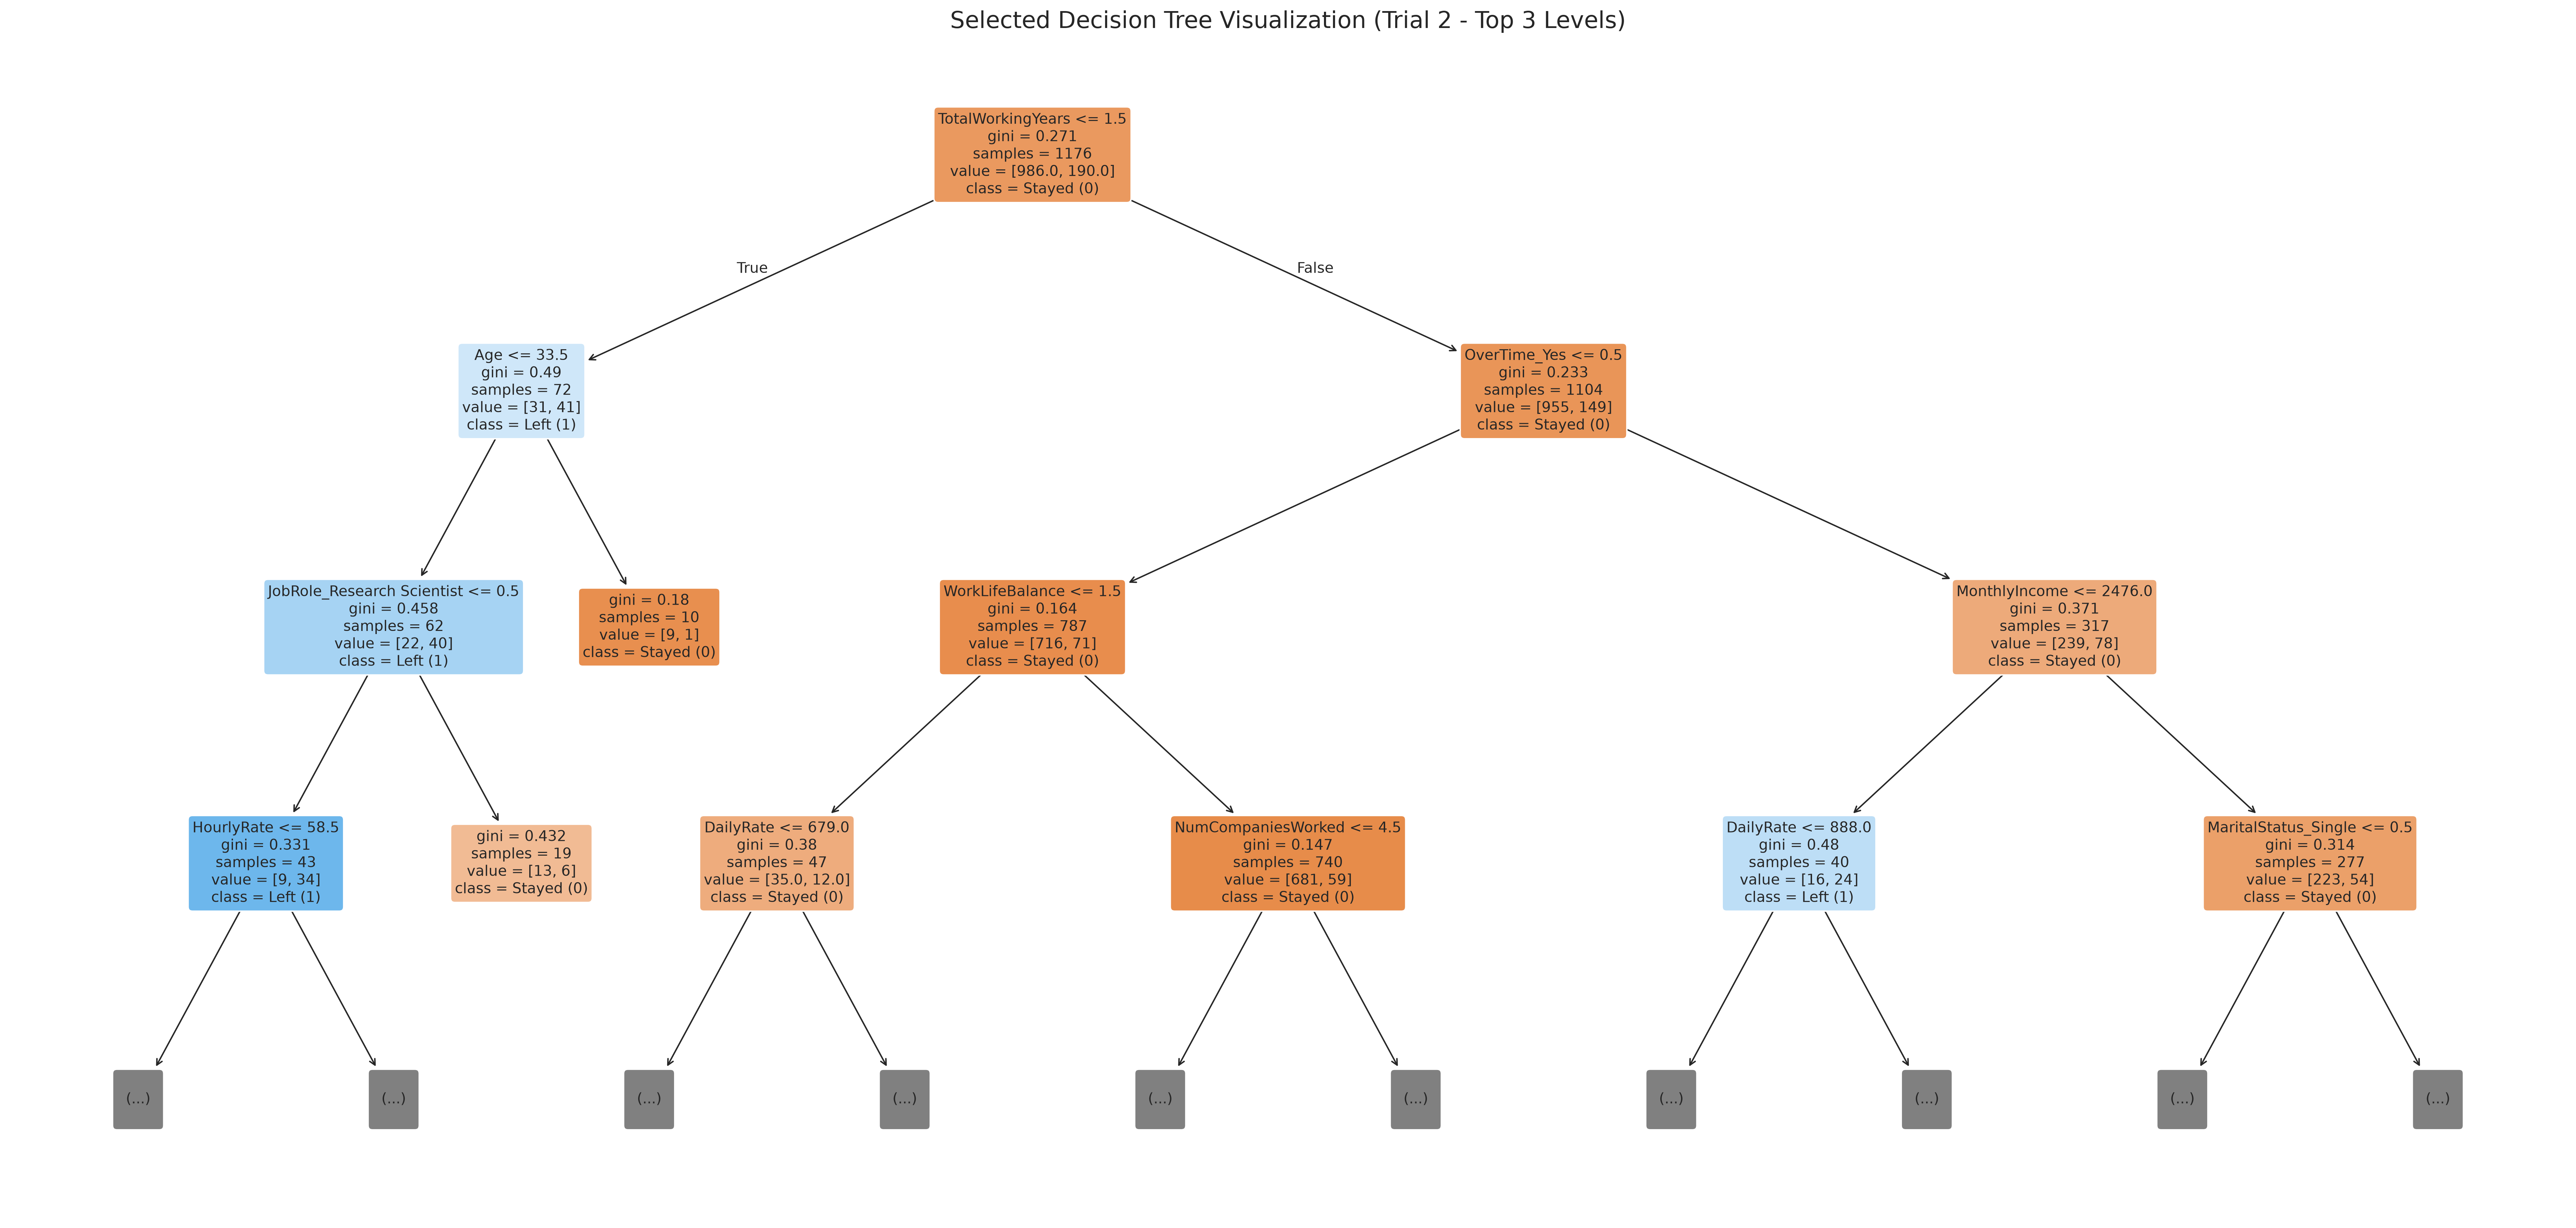

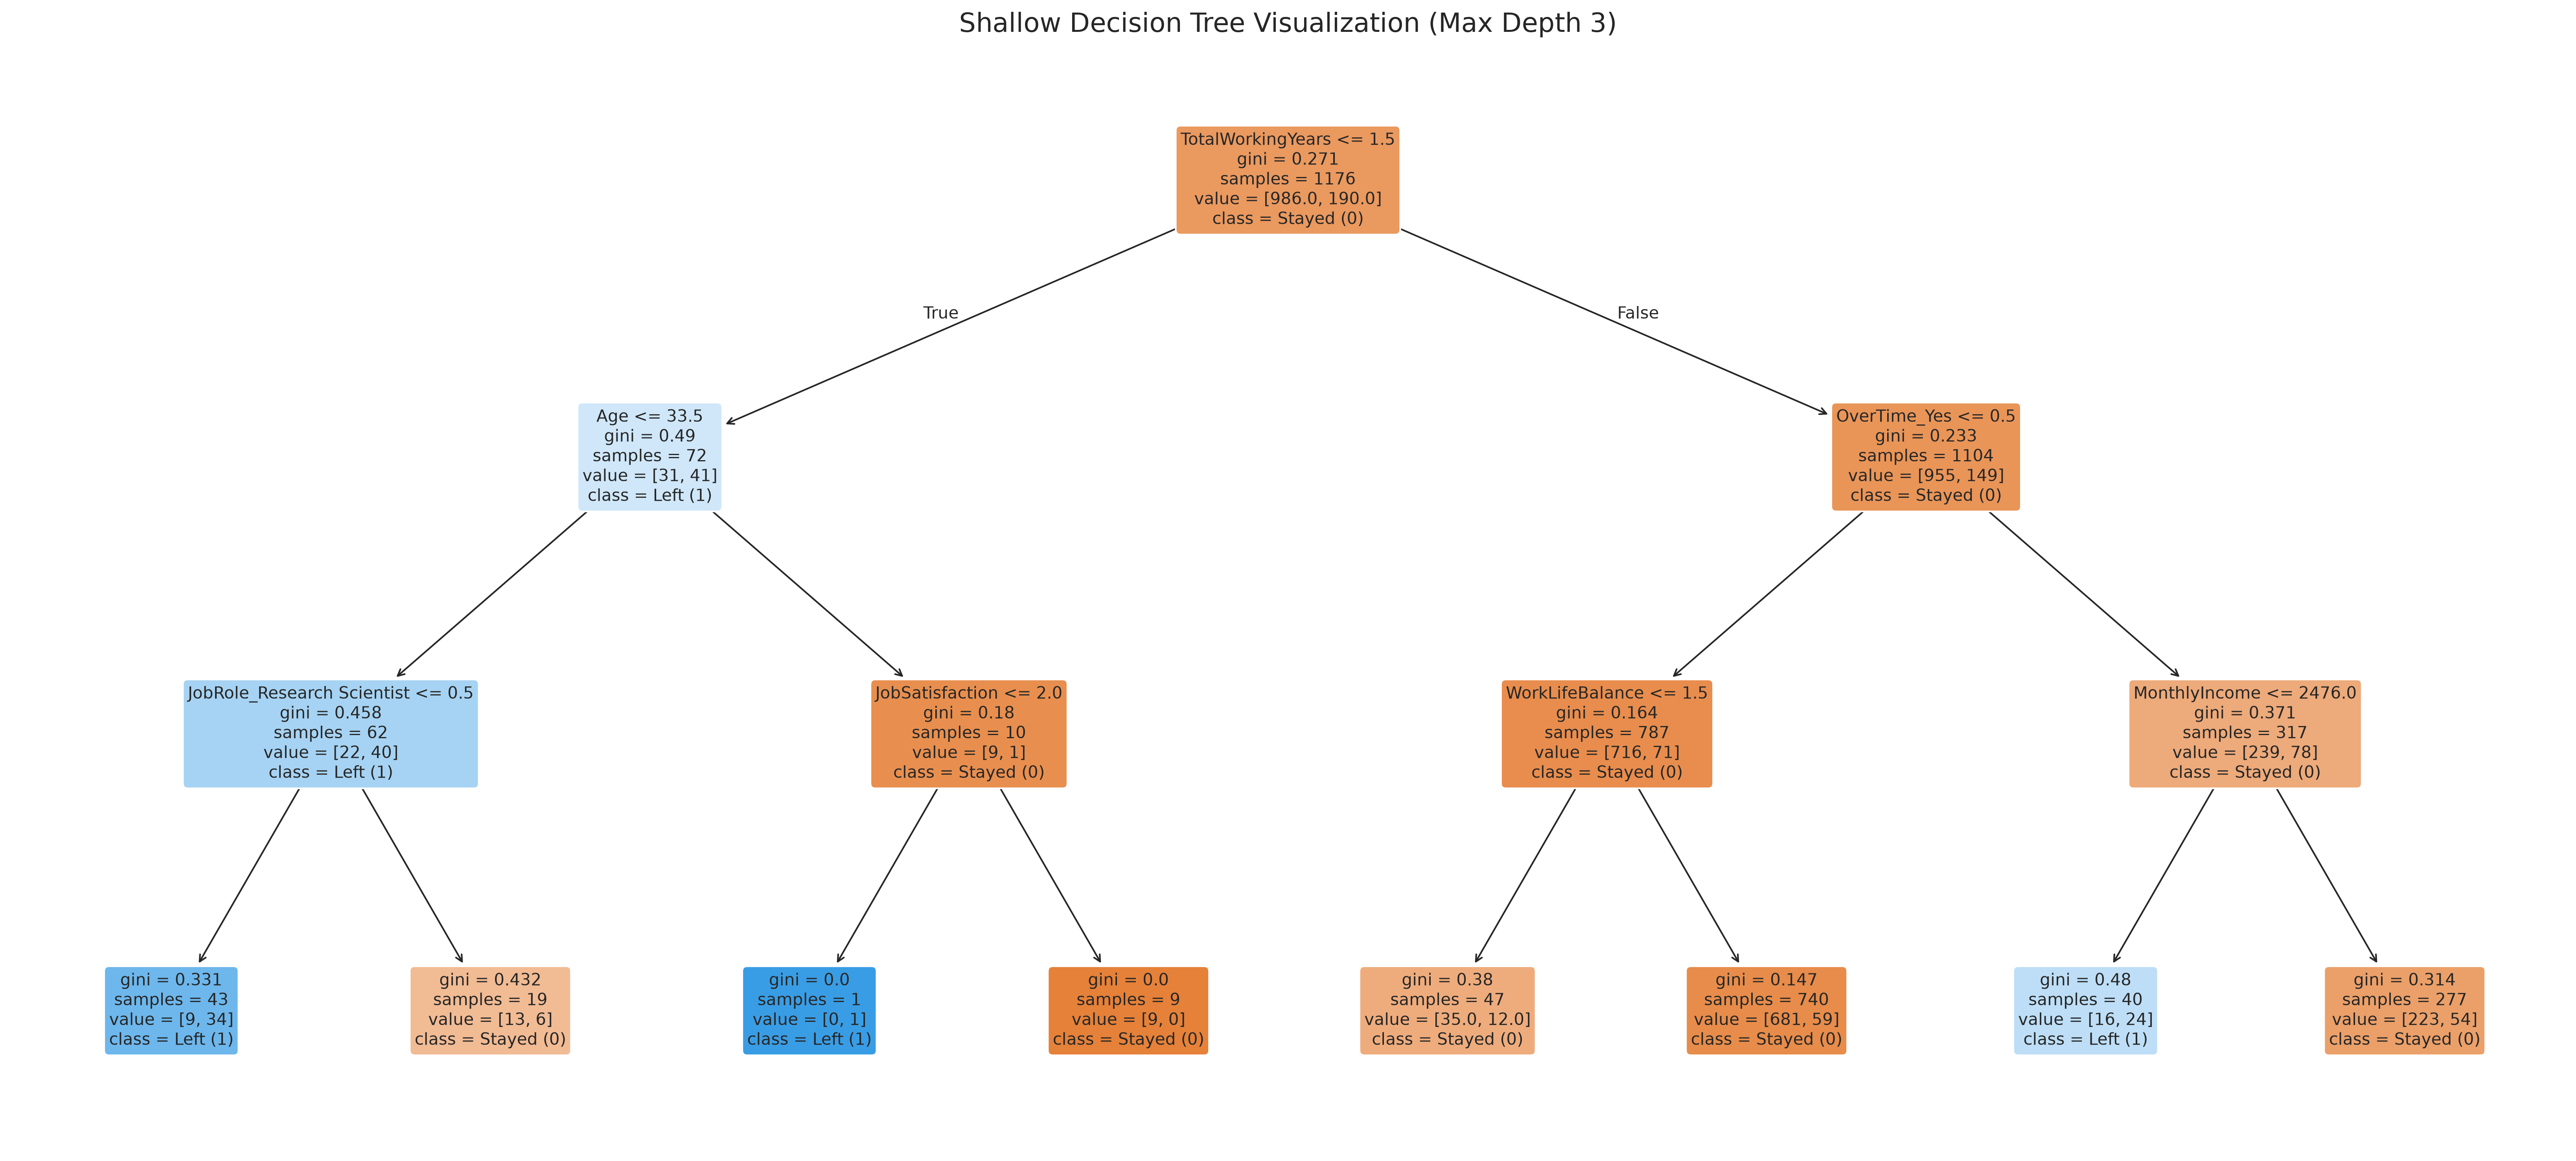

In [9]:
from sklearn.tree import plot_tree, DecisionTreeClassifier
import matplotlib.pyplot as plt

# 1. Re-instantiate and train your selected model (Trial 2)
selected_model = DecisionTreeClassifier(
    max_depth=8, 
    min_samples_split=20, 
    min_samples_leaf=10, 
    random_state=42
)
selected_model.fit(X_train, y_train)

# Plotting the Selected Model (Top 3 Levels for Readability)
plt.figure(figsize=(25, 12), dpi=300)
plot_tree(
    selected_model, 
    feature_names=X_train.columns.tolist(), 
    class_names=["Stayed (0)", "Left (1)"], 
    filled=True, 
    rounded=True, 
    max_depth=3,      # Restricts visual depth so text isn't cramped
    fontsize=10       # Larger, readable font
)
plt.title("Selected Decision Tree Visualization (Trial 2 - Top 3 Levels)", fontsize=16)
plt.tight_layout()
plt.savefig("selected_tree_readable.png", dpi=300, bbox_inches="tight") # Saves high-res file
plt.show()

# 2. Plotting a Clean Shallow Tree (Max Depth 3) for Comparison
shallow_model = DecisionTreeClassifier(max_depth=3, random_state=42)
shallow_model.fit(X_train, y_train)

plt.figure(figsize=(22, 10), dpi=300)
plot_tree(
    shallow_model, 
    feature_names=X_train.columns.tolist(), 
    class_names=["Stayed (0)", "Left (1)"], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Shallow Decision Tree Visualization (Max Depth 3)", fontsize=16)
plt.tight_layout()
plt.savefig("shallow_tree_readable.png", dpi=300, bbox_inches="tight") # Saves high-res file
plt.show()

### 1. Interpretation of Important Splits

Based on the visualized decision trees (examining the top decision rules), the model evaluates specific feature thresholds to determine employee attrition risk:

* **Root Node Split (`TotalWorkingYears <= 1.5`):**
The primary decision node splits employees based on their total tenure. If an employee has worked 1.5 years or less, they are routed down the left branch, which exhibits a much higher concentration of departures (Class 1 / Left). This indicates that early-career tenure is a critical window for employee retention.


* **Secondary Split for Junior Employees (`Age <= 33.5`):**
For employees with low tenure ($\le 1.5$ years), the tree further evaluates their age. Younger employees ($\le 33.5$ years old) combined with low tenure have an even higher propensity to leave, pointing toward younger entry-level turnover trends.


* **Secondary Split for Established Employees (`OverTime_Yes <= 0.5`):**
For employees with more than 1.5 years of experience (right branch), the next major decision rule evaluates whether they work overtime. Employees who work overtime (`OverTime_Yes > 0.5`) are immediately funneled toward higher attrition risk categories, emphasizing how burnout and long hours drive resignations among tenured staff.



---

### 2. Comparison of Visual and Structural Complexity

* **Shallow Tree (Max Depth 3):**
The shallow tree structure is compact, easy to inspect visually at a single glance, and straightforward to explain to stakeholders. However, because its depth is tightly capped, it stops splitting early, leaving broader leaf nodes that group mixed populations together, limiting its ability to capture nuanced behavioral patterns.


* **Selected Model Tree (Trial 2 - Max Depth 8 with Regularization):**
While capped at a maximum depth of 8 to prevent overfitting, this tree grows wider and more detailed (containing 44 leaves total) than a depth-3 tree. As seen in the expanded top layers, it captures fine-grained secondary interactions—such as how specific income tiers (`MonthlyIncome <= 2476.0`) or work-life balance scores interact with overtime and tenure. It strikes an optimal visual balance, remaining structured and interpretable while avoiding the chaotic fragmentation of an unconstrained baseline tree (which spanned 18 levels and 139 leaves).

## Reflection

1. How does a Decision Tree decide where to split the data?
- A Decision Tree evaluates every available feature and every possible threshold value within those features to find the split that best separates the data into distinct classes. It uses mathematical impurity metrics—such as Gini impurity or Entropy (Information Gain)—to measure the homogeneity of the resulting child nodes. The algorithm systematically selects the feature and split point that minimizes impurity, ensuring that the samples in the resulting child nodes are as pure (consisting of a single class) as possible.

2. What happened to model performance when max_depth was increased or decreased?
- Decreasing max_depth (such as Trial 1 at depth 4) restricted the tree's growth, causing the model to underfit. While it prevented memorizing training noise and slightly raised overall test accuracy, it failed to capture complex patterns, causing the minority class F1-score to drop sharply to 0.18.

Increasing max_depth (or leaving it unconstrained as in the baseline) allowed the tree to grow deep (depth of 18) until every leaf was pure. This resulted in 100% training accuracy due to severe overfitting, but degraded generalizability on the test set (testing accuracy dropped to 76.53%).

3. How did changing min_samples_split or min_samples_leaf affect the complexity and generalization of the tree?
- Increasing min_samples_split (e.g., requiring at least 20 samples to split a node) and min_samples_leaf (requiring at least 10 samples per leaf node) acted as powerful regularization constraints. They prevented the tree from generating tiny, hyper-specific branches based on isolated data points. This significantly reduced tree complexity—slashing the number of leaves from 139 down to a manageable 44—which successfully closed the gap between training and testing performance and improved overall generalization (boosting test accuracy to 84.69%).

4. Did gini and entropy produce the same tree and performance? Explain the differences you observed.
- No, they did not produce identical trees or performance. While both metrics measure node impurity (Gini measures variance-based impurity, while Entropy measures information theory-based disorder), they calculate split thresholds differently. In our experiments, the Gini-based configuration (Trial 2) achieved a higher testing accuracy (84.69%) and a better minority class F1-score (0.38) compared to the Entropy-based configuration (Trial 3, testing accuracy 81.97%, F1-score 0.31), indicating that Gini captured more effective splits for this specific HR dataset.

5. Which experimental configuration provided the best balance between training performance, testing performance, and tree complexity? Support - your answer with evidence from your results.
Trial 2 (max_depth=8, min_samples_split=20, min_samples_leaf=10) provided the best overall balance.

- Evidence: It successfully eliminated the extreme overfitting of the baseline (reducing training accuracy to a healthier 89.46% while raising test accuracy to its peak of 84.69%). Furthermore, it maintained a controlled, interpretable tree structure (depth of 8 and 44 leaves) while achieving a strong minority-class F1-score of 0.38.

6. What are the advantages and limitations of Decision Trees for your chosen dataset?
Advantages:

- High Interpretability: Decision trees produce clear, visual IF-THEN rules that allow HR managers to easily understand what drives employee attrition (e.g., low tenure combined with overtime).

- Mixed Data Support: They natively handle a combination of numerical attributes (MonthlyIncome, Age) and one-hot encoded categorical variables (JobRole, BusinessTravel) without requiring feature scaling or normalization.

Limitations:

- Overfitting Sensitivity: Unconstrained trees easily overfit by memorizing training noise, requiring careful parameter tuning.

- Class Imbalance Struggles: Standard trees naturally favor the majority class (employees who stayed), requiring explicit split constraints or class weighting to avoid missing minority-class outcomes (employees who leave).